# D-4: Churn prediction model (scikit-learn)
**Question:** does repair use still lower churn **after controlling for everything else at once** (how often a
customer shops, how recently, how much they spend, loyalty tier, age, channel)? C-1 matched on age and spend;
a model controls for many more things together. It also gives leadership a list of at-risk customers.

**Design (no leakage):** pick a cutoff date **T = 30 Apr 2026**. Every feature uses only data **up to T**.
The label is whether the customer **churns in the next 180 days** (no visit from 1 May to 27 Oct 2026).
Population: customers with at least one visit in the 12 months before T (6,129 "current" customers).

**Models:** logistic regression (interpretable: odds ratios) and gradient-boosted trees (flexible, non-linear),
trained on 75% of customers and scored on the other 25%.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from src import config as C
from src.metrics import load

OUT = ROOT / "results" / "d_customers_arr"
BLUE, ORANGE = "#2a78d6", "#eb6834"
INK, INK2, GRID = "#0b0b0b", "#5f5e5a", "#e4e3df"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "font.size": 11,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
})

T = pd.Timestamp("2026-04-30")
HORIZON = 180
SEED = 42

## 1. Build features (as of T) and the label (after T)

In [2]:
visits = load("visits")
customers = load("customers")

past = visits[visits["date"] <= T]
future = visits[(visits["date"] > T) & (visits["date"] <= T + pd.Timedelta(days=HORIZON))]
last12 = past[past["date"] > T - pd.Timedelta(days=365)]

pop = customers.set_index("customer_id").loc[last12["customer_id"].unique()].copy()

g12 = last12.groupby("customer_id")
pop["visits_12m"] = g12.size()
pop["purchase_visits_12m"] = g12["has_purchase"].sum()
pop["revenue_12m"] = g12["revenue"].sum()
pop["redeemed_12m"] = g12["redeemed_dollars"].sum()
pop["returns_12m"] = g12["has_return"].sum()
pop["days_since_last_purchase"] = (T - past[past["has_purchase"]].groupby("customer_id")["date"].max()).dt.days
pop["days_since_last_purchase"] = pop["days_since_last_purchase"].fillna(730)
pop["tenure_years"] = (T - pop["signup_date"]).dt.days / 365
pop["member"] = (pop["loyalty_join_date"] <= T).fillna(False).astype(int)
last_tier = past.sort_values("datetime").groupby("customer_id")["tier"].last()
pop["silver_or_gold"] = last_tier.reindex(pop.index).isin(["Silver", "Gold"]).astype(int)
drop = past[past["has_dropoff"]].groupby("customer_id").size()
pop["used_repair"] = (drop.reindex(pop.index).fillna(0) > 0).astype(int)

# Label: no visit of any kind in the next 180 days (the team's churn definition)
pop["churn"] = (~pop.index.isin(future["customer_id"])).astype(int)
# Robustness label: no PURCHASE in the next 180 days (a pickup trip doesn't count as staying)
pop["churn_purchase"] = (~pop.index.isin(future.loc[future["has_purchase"], "customer_id"])).astype(int)

NUM = ["visits_12m", "purchase_visits_12m", "revenue_12m", "redeemed_12m", "returns_12m",
       "days_since_last_purchase", "tenure_years"]
BIN = ["used_repair", "member", "silver_or_gold",
       "interest_run", "interest_yoga", "interest_pilates", "interest_outdoor", "interest_lifestyle"]
CAT = ["age_band", "acquisition_channel", "home_area"]

print(f"{len(pop):,} customers · churn rate {pop['churn'].mean():.1%} · repair users {pop['used_repair'].mean():.1%}")
pop.groupby("used_repair")[["churn", "churn_purchase", "visits_12m", "revenue_12m"]].mean().round(2)

6,129 customers · churn rate 42.1% · repair users 29.2%


,churn,churn_purchase,visits_12m,revenue_12m
used_repair,,,,
0,0.53,0.53,3.99,501.26
1,0.16,0.16,19.84,2577.97


## 2. Train and score both models

In [3]:
X, y = pop[NUM + BIN + CAT], pop["churn"]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, stratify=y, random_state=SEED)

prep = ColumnTransformer([
    ("num", StandardScaler(), NUM),
    ("bin", "passthrough", BIN),
    ("cat", OneHotEncoder(handle_unknown="ignore", drop="first"), CAT),
])
logit = Pipeline([("prep", prep), ("model", LogisticRegression(max_iter=2000))]).fit(X_tr, y_tr)

prep_gb = ColumnTransformer([
    ("num", "passthrough", NUM + BIN),
    ("cat", OneHotEncoder(handle_unknown="ignore"), CAT),
], sparse_threshold=0)
gbm = Pipeline([("prep", prep_gb),
                ("model", HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, random_state=SEED))]).fit(X_tr, y_tr)

scores = pd.Series({
    "Logistic regression": roc_auc_score(y_te, logit.predict_proba(X_te)[:, 1]),
    "Gradient-boosted trees": roc_auc_score(y_te, gbm.predict_proba(X_te)[:, 1]),
    "Logistic, repair use removed": roc_auc_score(
        y_te, Pipeline([("prep", ColumnTransformer([("num", StandardScaler(), NUM),
                                                     ("bin", "passthrough", [b for b in BIN if b != "used_repair"]),
                                                     ("cat", OneHotEncoder(handle_unknown="ignore", drop="first"), CAT)])),
                        ("model", LogisticRegression(max_iter=2000))]).fit(X_tr, y_tr).predict_proba(X_te)[:, 1]),
}, name="test AUC").round(3)
scores   # AUC: 0.5 = coin flip, 1.0 = perfect ranking of who churns

Logistic regression             0.843
Gradient-boosted trees          0.838
Logistic, repair use removed    0.842
Name: test AUC, dtype: float64

## 3. Does repair use still lower churn, holding everything else fixed?
**Odds ratios** from the logistic regression: below 1 = lowers churn odds, above 1 = raises them.
Numeric features are per one standard deviation.

**Effect in percentage points:** for each repair user, predict churn as they are, then again with
`used_repair` switched off, everything else unchanged. The average difference is the repair effect after
controls (both models, all customers).

In [4]:
names = (NUM + BIN + list(logit.named_steps["prep"].named_transformers_["cat"].get_feature_names_out(CAT)))
odds = pd.Series(np.exp(logit.named_steps["model"].coef_[0]), index=names).sort_values()


def repair_effect(model, data):
    users = data[data["used_repair"] == 1]
    p_on = model.predict_proba(users)[:, 1]
    p_off = model.predict_proba(users.assign(used_repair=0))[:, 1]
    return (p_on.mean() - p_off.mean()) * 100, p_on.mean() * 100, p_off.mean() * 100


rows = {}
for label, target in [("churn (any visit)", "churn"), ("churn (purchase visits only)", "churn_purchase")]:
    yy = pop[target]
    lg = Pipeline([("prep", prep), ("model", LogisticRegression(max_iter=2000))]).fit(X, yy)
    gb = Pipeline([("prep", prep_gb), ("model", HistGradientBoostingClassifier(
        max_iter=300, learning_rate=0.05, random_state=SEED))]).fit(X, yy)
    raw = pop.groupby("used_repair")[target].mean() * 100
    rows[label] = {
        "raw gap (pts)": raw[1] - raw[0],
        "logistic: effect after controls (pts)": repair_effect(lg, X)[0],
        "boosted trees: effect after controls (pts)": repair_effect(gb, X)[0],
        "logistic odds ratio for repair use": np.exp(lg.named_steps["model"].coef_[0][names.index("used_repair")]),
    }
effect = pd.DataFrame(rows).T.round(2)
effect

,raw gap (pts),logistic: effect after controls (pts),boosted trees: effect after controls (pts),logistic odds ratio for repair use
churn (any visit),-37.17,-8.62,-5.27,0.49
churn (purchase visits only),-37.01,-8.41,-4.95,0.51


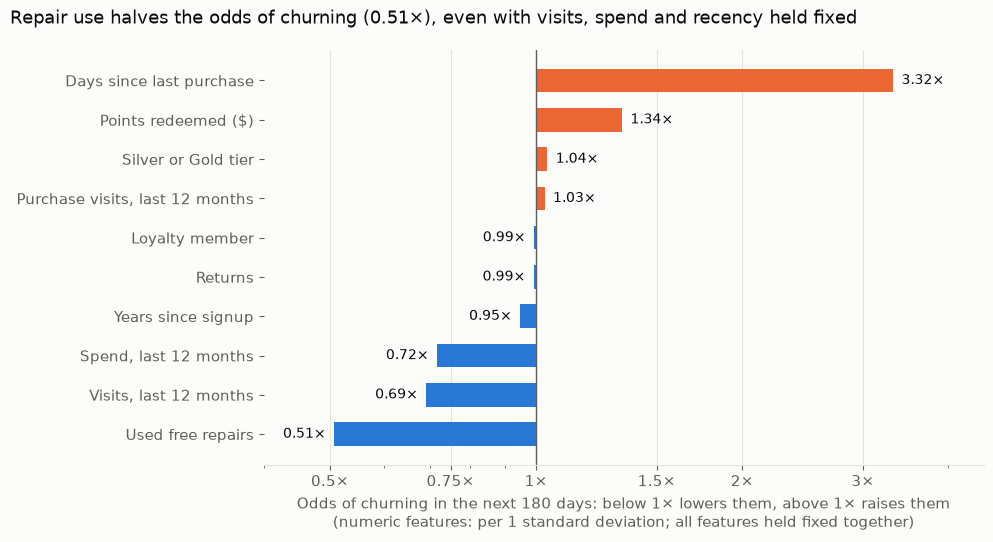

In [5]:
LABELS = {
    "used_repair": "Used free repairs", "member": "Loyalty member", "silver_or_gold": "Silver or Gold tier",
    "visits_12m": "Visits, last 12 months", "purchase_visits_12m": "Purchase visits, last 12 months",
    "revenue_12m": "Spend, last 12 months", "redeemed_12m": "Points redeemed ($)", "returns_12m": "Returns",
    "days_since_last_purchase": "Days since last purchase", "tenure_years": "Years since signup",
}
show = odds[odds.index.isin(LABELS)].rename(LABELS).sort_values()

fig, ax = plt.subplots(figsize=(10, 5.5))
colors = [BLUE if v < 1 else ORANGE for v in show.values]
ax.barh(show.index, show.values - 1, left=1, color=colors, height=0.6)
ax.axvline(1, color=INK2, lw=1)
ax.set_xscale("log")
ticks = [0.5, 0.75, 1, 1.5, 2, 3]
ax.set_xticks(ticks)
ax.set_xticklabels([f"{t:g}×" for t in ticks])
ax.set_xlim(0.4, 4.5)
for name, val in show.items():
    ax.annotate(f"{val:.2f}×", (val, name), xytext=(6 if val >= 1 else -6, 0), textcoords="offset points",
                ha="left" if val >= 1 else "right", va="center", color=INK, fontsize=10)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Odds of churning in the next 180 days: below 1× lowers them, above 1× raises them\n"
              "(numeric features: per 1 standard deviation; all features held fixed together)")
r = odds["used_repair"]
ax.xaxis.set_minor_formatter(plt.NullFormatter())
fig.suptitle(f"Repair use halves the odds of churning ({r:.2f}×), even with visits, spend and recency held fixed",
             x=0.01, ha="left", color=INK, fontsize=13)
fig.tight_layout()
fig.savefig(OUT / "d3_churn_odds.png", dpi=200)
plt.show()

## 4. Who is at risk now (for leadership)
Refit on everything up to the **end of the data (31 Oct 2026)** with the same features, and score current
customers. "At risk" = predicted churn probability of 60% or more in the next 180 days.

In [6]:
T_NOW = C.DATA_END
past_now = visits[visits["date"] <= T_NOW]
last12_now = past_now[past_now["date"] > T_NOW - pd.Timedelta(days=365)]
cur = customers.set_index("customer_id").loc[last12_now["customer_id"].unique()].copy()
gn = last12_now.groupby("customer_id")
cur["visits_12m"] = gn.size()
cur["purchase_visits_12m"] = gn["has_purchase"].sum()
cur["revenue_12m"] = gn["revenue"].sum()
cur["redeemed_12m"] = gn["redeemed_dollars"].sum()
cur["returns_12m"] = gn["has_return"].sum()
cur["days_since_last_purchase"] = (T_NOW - past_now[past_now["has_purchase"]].groupby("customer_id")["date"].max()).dt.days
cur["days_since_last_purchase"] = cur["days_since_last_purchase"].fillna(730)
cur["tenure_years"] = (T_NOW - cur["signup_date"]).dt.days / 365
cur["member"] = (cur["loyalty_join_date"] <= T_NOW).fillna(False).astype(int)
lt = past_now.sort_values("datetime").groupby("customer_id")["tier"].last()
cur["silver_or_gold"] = lt.reindex(cur.index).isin(["Silver", "Gold"]).astype(int)
dn = past_now[past_now["has_dropoff"]].groupby("customer_id").size()
cur["used_repair"] = (dn.reindex(cur.index).fillna(0) > 0).astype(int)

final = Pipeline([("prep", prep_gb), ("model", HistGradientBoostingClassifier(
    max_iter=300, learning_rate=0.05, random_state=SEED))]).fit(X, y)   # trained on the T = Apr 2026 snapshot
cur["p_churn"] = final.predict_proba(cur[NUM + BIN + CAT])[:, 1]
at_risk = cur[cur["p_churn"] >= 0.6]
pd.Series({
    "current customers scored": len(cur),
    "at risk (p ≥ 60%)": len(at_risk),
    "ARR held by at-risk customers ($)": at_risk["arr_12m"].sum(),
    "share of total ARR (%)": at_risk["arr_12m"].sum() / customers["arr_12m"].sum() * 100,
    "at-risk customers who use repairs (%)": at_risk["used_repair"].mean() * 100,
}).round(1)

current customers scored                   6100.0
at risk (p ≥ 60%)                          1864.0
ARR held by at-risk customers ($)        648823.9
share of total ARR (%)                        9.7
at-risk customers who use repairs (%)        14.5
dtype: float64

## 5. Caveats
- This is still **observational**: the model controls for what we can measure (frequency, recency, spend, tier,
  demographics), not for unmeasured engagement. The repair effect after controls is evidence, not proof.
- Visits include repair pickups. The purchase-only label checks that pickup trips aren't creating the effect.
- One snapshot (T = 30 Apr 2026). The at-risk list applies a model trained on that snapshot to Oct 2026 data.